In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

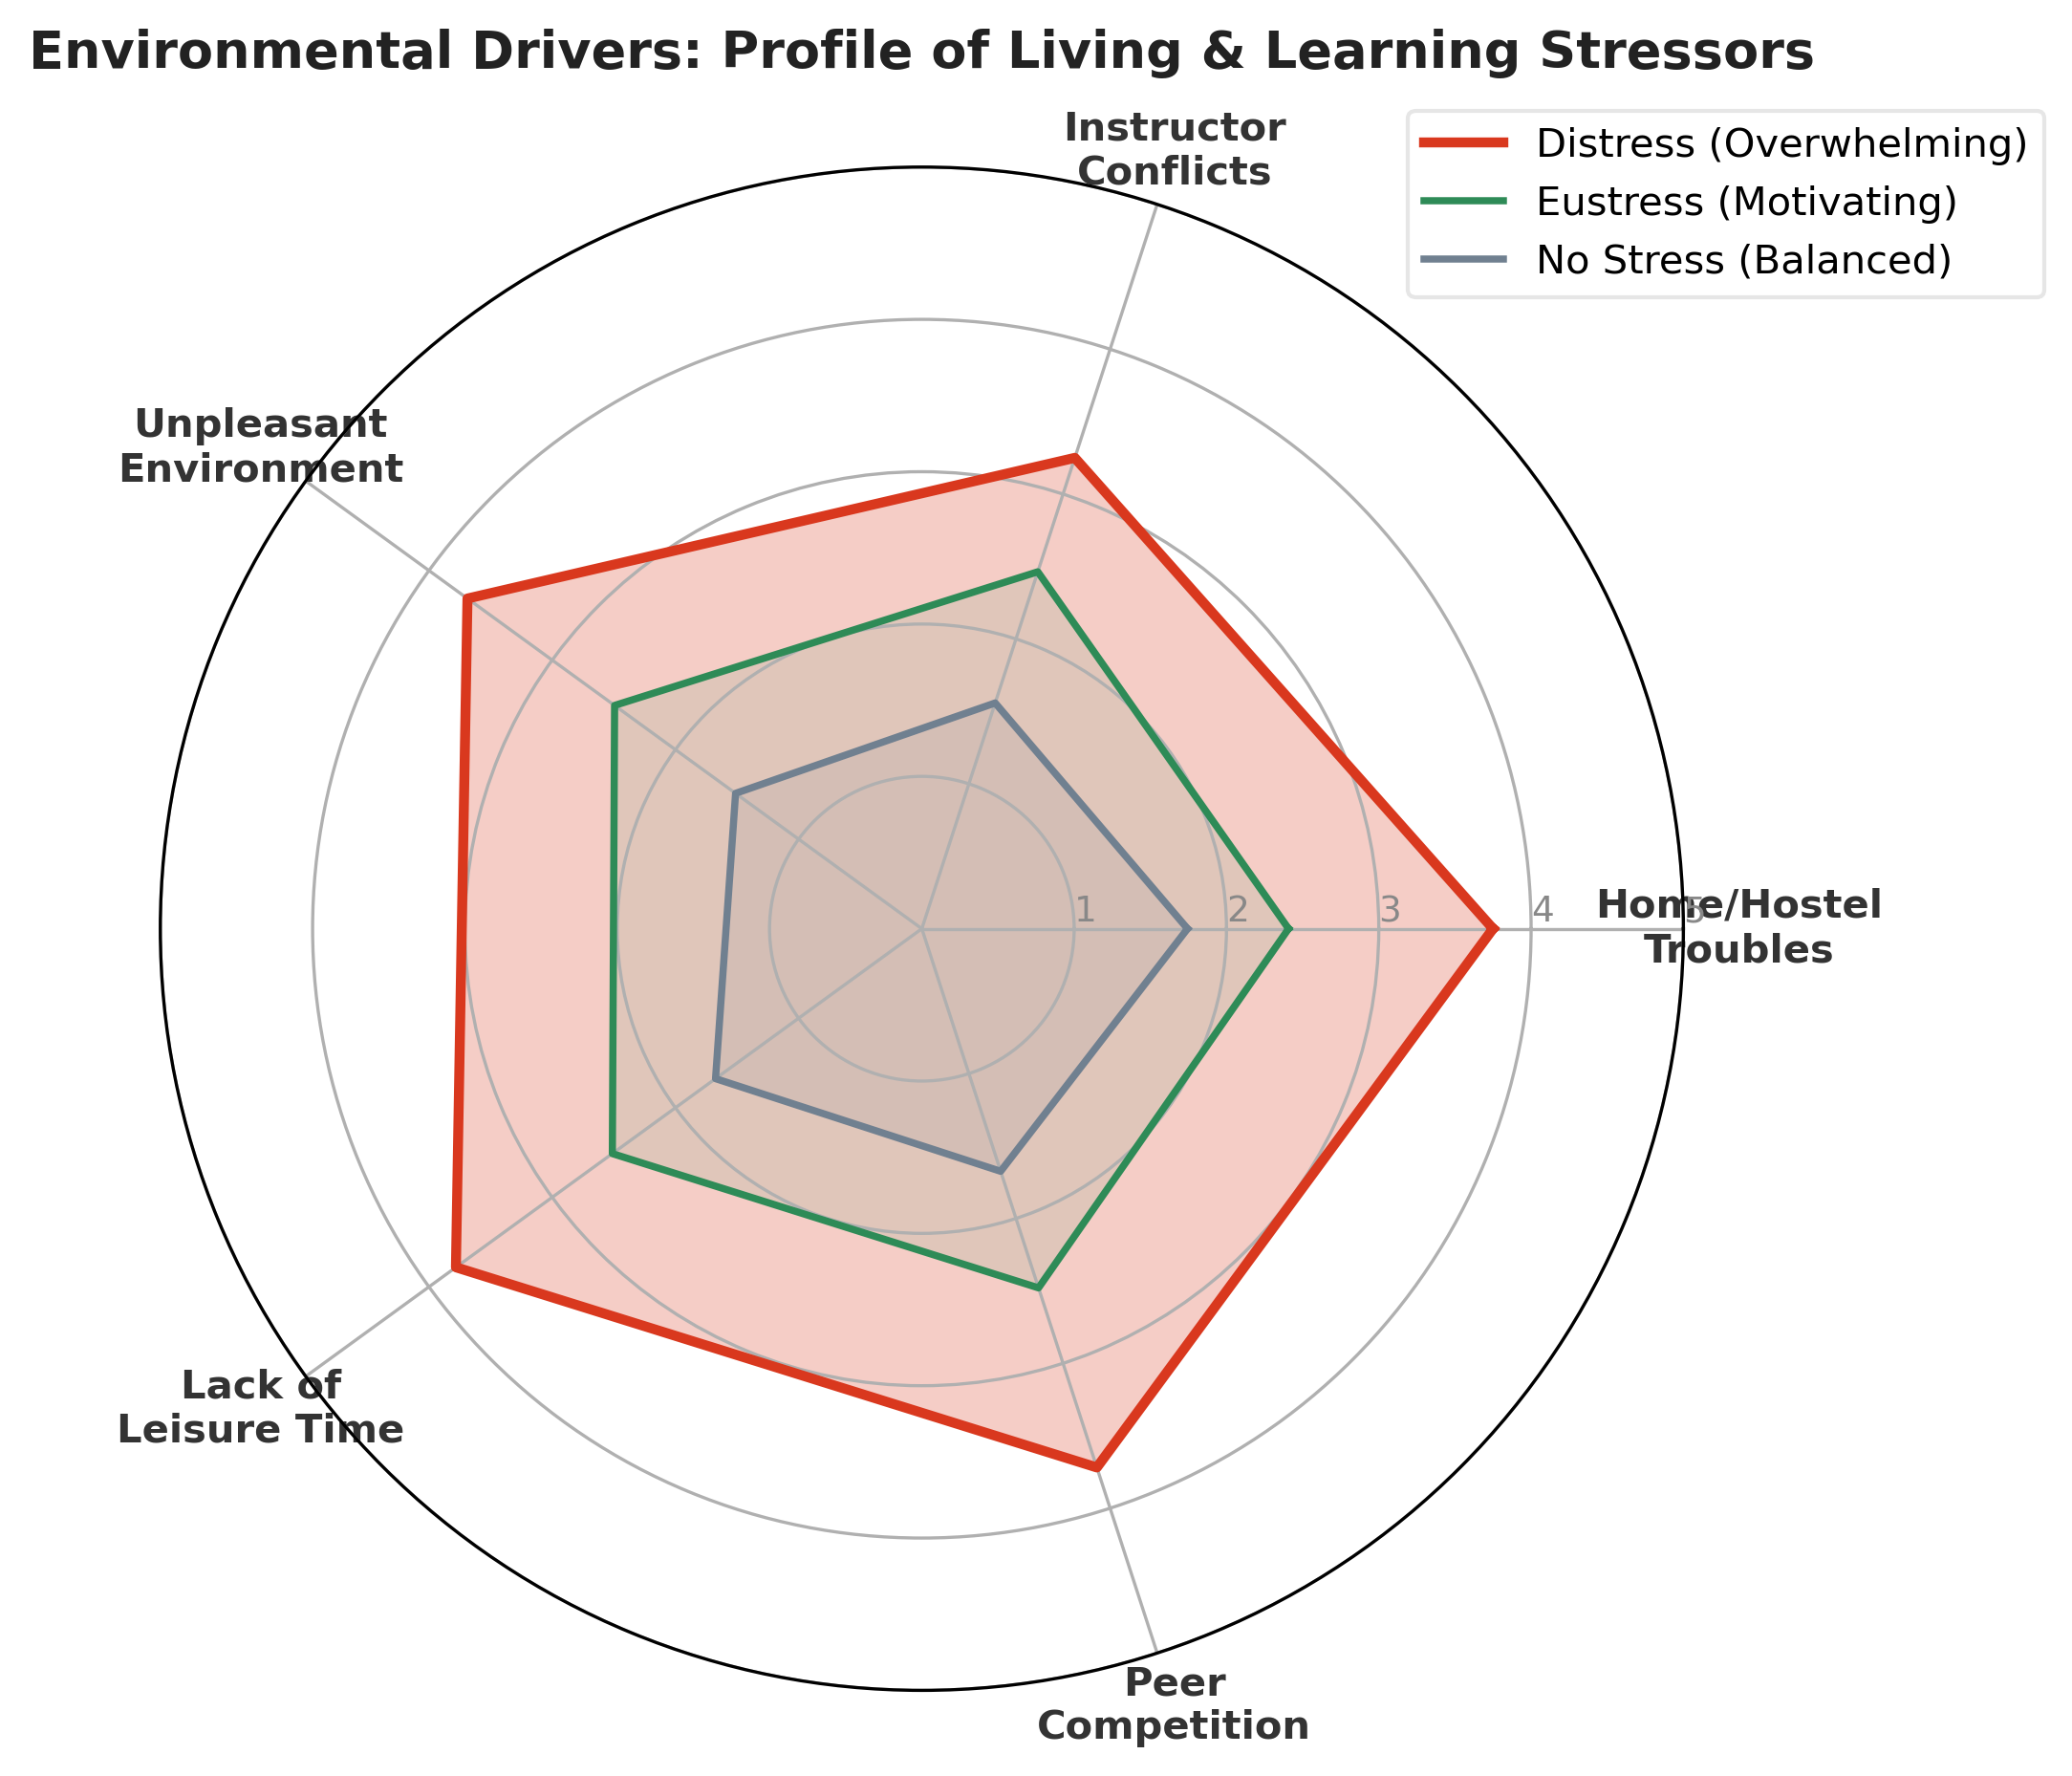

In [10]:
df = pd.read_csv('Stress_Dataset.csv')

df['Stress_Short'] = df['Which type of stress do you primarily experience?'].map({
    'Eustress (Positive Stress) - Stress that motivates and enhances performance.': 'Eustress (Motivating)',
    'No Stress - Currently experiencing minimal to no stress.': 'No Stress (Balanced)',
    'Distress (Negative Stress) - Stress that causes anxiety and impairs well-being.': 'Distress (Overwhelming)'
})

env_factors = [
    'Is your hostel or home environment causing you difficulties?',
    'Are you facing any difficulties with your professors or instructors?',
    'Is your working environment unpleasant or stressful?',
    'Do you struggle to find time for relaxation and leisure activities?',
    'Are you in competition with your peers, and does it affect you?'
]

factor_labels = [
    'Home/Hostel\nTroubles',
    'Instructor\nConflicts',
    'Unpleasant\nEnvironment',
    'Lack of\nLeisure Time',
    'Peer\nCompetition'
]

radar_df = df.groupby('Stress_Short')[env_factors].mean()
radar_df.columns = factor_labels

categories = factor_labels
N = len(categories)

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True), dpi=300)

colors = {
    'Distress (Overwhelming)': '#D9381E', 
    'Eustress (Motivating)': '#2E8B57',    
    'No Stress (Balanced)': '#708090' 
}

for group in ['Distress (Overwhelming)', 'Eustress (Motivating)', 'No Stress (Balanced)']:
    values = radar_df.loc[group].values.flatten().tolist()
    values += values[:1]
    
    linewidth = 2.5 if 'Distress' in group else 1.8
    alpha = 0.25 if 'Distress' in group else 0.1
    
    ax.plot(angles, values, linewidth=linewidth, linestyle='solid', label=group, color=colors[group])
    ax.fill(angles, values, color=colors[group], alpha=alpha)

plt.xticks(angles[:-1], categories, size=10, fontweight='bold', color='#333333')

ax.set_rlabel_position(0)
plt.yticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5"], color="#888888", size=9)
plt.ylim(0, 5)

plt.title('Environmental Drivers: Profile of Living & Learning Stressors', size=13, fontweight='bold', pad=25, color='#222222')
plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1.05), frameon=True, facecolor='white', edgecolor='#E0E0E0')

plt.tight_layout()
plt.show()